# B4. Konvolusi dan Penapisan Spasial (SIMUTEH, SEED 1014)

In [1]:
import sys, time
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil, kontras_bercak

## Langkah 4.1 Pemeriksaan lembar hitung manual dengan kode

In [2]:
P = np.array([[52,55,61,58],[59,255,64,60],[62,60,0,57],[58,61,59,63]], float)
gk = np.array([[1,2,1],[2,4,2],[1,2,1]]) / 16
rer = np.zeros((2, 2)); gau = np.zeros((2, 2)); med = np.zeros((2, 2))
for y in range(2):
    for x in range(2):
        w = P[y:y+3, x:x+3]
        rer[y, x] = w.mean(); gau[y, x] = (w * gk).sum(); med[y, x] = np.median(w)
print("rerata:\n", rer.round(2)); print("gaussian:\n", gau.round(2)); print("median:\n", med)
Q = np.array([[70,72,75],[74,120,78],[73,76,79]], float)
ks = np.array([[0,-1,0],[-1,5,-1],[0,-1,0]], float)
v = (Q * ks).sum(); print("kernel tajam pusat Q:", v, "-> clip", int(np.clip(v, 0, 255)))
baris = np.array([12, 30, 45, 70])
for nm, mode in [("zero", "constant"), ("replicate", "edge"), ("reflect101", "reflect")]:
    pad = np.pad(baris, 1, mode=mode)
    print(f"{nm:10s} pad={pad.tolist()} rerata 1x3 piksel pertama = {pad[:3].mean():.2f}")

rerata:
 [[74.22 74.44]
 [75.33 75.44]]
gaussian:
 [[104.44  77.38]
 [ 77.25  57.44]]
median:
 [[60. 60.]
 [60. 60.]]
kernel tajam pusat Q: 300.0 -> clip 255
zero       pad=[0, 12, 30, 45, 70, 0] rerata 1x3 piksel pertama = 14.00
replicate  pad=[12, 12, 30, 45, 70, 70] rerata 1x3 piksel pertama = 18.00
reflect101 pad=[30, 12, 30, 45, 70, 45] rerata 1x3 piksel pertama = 24.00


## Langkah 4.2 Konvolusi manual vs cv2.filter2D

In [3]:
def konvolusi(img, k):  # fungsi dari slide P4
    kh, kw = k.shape; ph, pw = kh // 2, kw // 2
    pad = np.pad(img.astype(float), ((ph, ph), (pw, pw)), mode="edge")
    out = np.zeros(img.shape)
    for y in range(img.shape[0]):
        for x in range(img.shape[1]):
            out[y, x] = np.sum(pad[y:y+kh, x:x+kw] * k)
    return np.clip(np.round(out), 0, 255).astype(np.uint8)

def konvolusi_sejati(img, k):  # kernel dibalik 180 derajat dahulu
    return konvolusi(img, np.flip(k))

nama = "teh_041.png"
bersih = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nama}"), cv2.COLOR_BGR2GRAY)
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
for nm, k in {"rerata": np.ones((3, 3)) / 9,
              "asimetris": np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]], float)}.items():
    t0 = time.perf_counter(); a = konvolusi(bersih, k); t_manual = time.perf_counter() - t0
    t0 = time.perf_counter(); b = cv2.filter2D(bersih, -1, k, borderType=cv2.BORDER_REPLICATE); t_cv = time.perf_counter() - t0
    beda = np.abs(a.astype(int) - b.astype(int)).max()
    c = konvolusi_sejati(bersih, k)
    beda2 = np.abs(c.astype(int) - b.astype(int)).max()
    print(f"{nm}: selisih manual vs filter2D={beda}, sejati vs filter2D={beda2}, "
          f"waktu manual={t_manual:.3f} s, filter2D={t_cv:.5f} s")

rerata: selisih manual vs filter2D=0, sejati vs filter2D=0, waktu manual=1.065 s, filter2D=0.00716 s
asimetris: selisih manual vs filter2D=0, sejati vs filter2D=255, waktu manual=1.027 s, filter2D=0.00043 s


## Langkah 4.3 Enam penapis dan lima derau

In [4]:
rng = np.random.default_rng(42)
def derau_gauss(img, sd):
    return np.clip(img + rng.normal(0, sd, img.shape), 0, 255).astype(np.uint8)
def derau_sp(img, p):  # p = proporsi piksel rusak
    out = img.copy(); m = rng.random(img.shape)
    out[m < p / 2] = 0; out[m > 1 - p / 2] = 255
    return out
def ukur_waktu(f, x, ulang=20):  # rerata beberapa kali, dalam ms
    t = []
    for _ in range(ulang):
        t0 = time.perf_counter(); f(x); t.append(time.perf_counter() - t0)
    return 1000 * np.mean(t)

derau = {"gauss_10": derau_gauss(bersih, 10), "gauss_20": derau_gauss(bersih, 20),
         "gauss_40": derau_gauss(bersih, 40), "sp_4%": derau_sp(bersih, 0.04),
         "sp_10%": derau_sp(bersih, 0.10)}
penapis = {"rerata_3": lambda x: cv2.blur(x, (3, 3)),
           "rerata_5": lambda x: cv2.blur(x, (5, 5)),
           "gauss_5": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
           "median_3": lambda x: cv2.medianBlur(x, 3),
           "median_5": lambda x: cv2.medianBlur(x, 5),
           "median_9": lambda x: cv2.medianBlur(x, 9)}
baris = []
for dn, d in derau.items():
    baris.append([dn, "tanpa", cv2.PSNR(bersih, d), 0.0, kontras_bercak(d, md, mb)])
    for pn, f in penapis.items():
        out = f(d)
        baris.append([dn, pn, cv2.PSNR(bersih, out), ukur_waktu(f, d), kontras_bercak(out, md, mb)])
tabel = pd.DataFrame(baris, columns=["derau", "penapis", "PSNR_dB", "waktu_ms", "KB"]).round(2)
print(tabel.to_string())
tabel.to_csv("../hasil/b4_tabel_penapis.csv", index=False)
print("KB citra bersih tanpa derau:", round(kontras_bercak(bersih, md, mb), 2))

       derau   penapis  PSNR_dB  waktu_ms    KB
0   gauss_10     tanpa    28.11      0.00  3.68
1   gauss_10  rerata_3    36.86      0.18  5.97
2   gauss_10  rerata_5    37.57      0.23  6.15
3   gauss_10   gauss_5    37.68      0.08  6.14
4   gauss_10  median_3    35.49      0.05  5.87
5   gauss_10  median_5    38.40      0.43  6.75
6   gauss_10  median_9    38.51      7.88  7.59
7   gauss_20     tanpa    22.11      0.00  2.07
8   gauss_20  rerata_3    31.41      0.20  4.66
9   gauss_20  rerata_5    34.45      0.27  5.50
10  gauss_20   gauss_5    32.55      0.06  4.99
11  gauss_20  median_3    29.73      0.05  4.20
12  gauss_20  median_5    33.42      0.46  5.41
13  gauss_20  median_9    35.37      8.55  6.06
14  gauss_40     tanpa    16.39      0.00  1.06
15  gauss_40  rerata_3    25.85      0.18  2.92
16  gauss_40  rerata_5    29.76      0.23  4.09
17  gauss_40   gauss_5    27.06      0.06  3.27
18  gauss_40  median_3    23.82      0.05  2.44
19  gauss_40  median_5    27.82      0.3

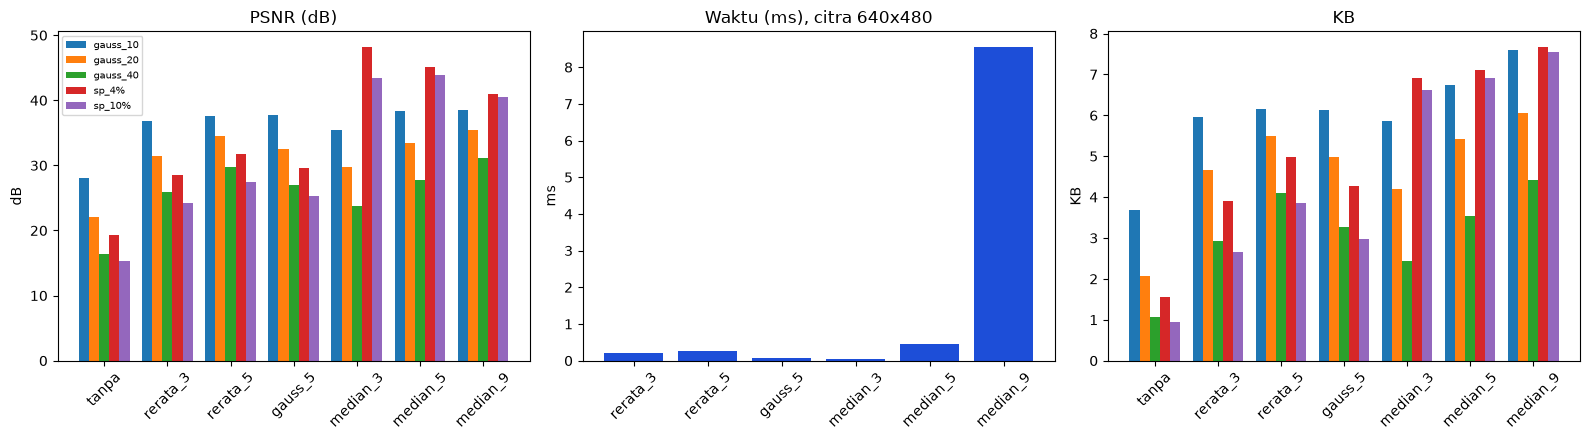

In [5]:
# grafik PSNR dan waktu untuk seluruh hasil
urut = ["tanpa"] + list(penapis)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
lebar = 0.16
for i, dn in enumerate(derau):
    t = tabel[tabel.derau == dn].set_index("penapis").loc[urut]
    ax[0].bar(np.arange(len(urut)) + i * lebar, t.PSNR_dB, lebar, label=dn)
    ax[2].bar(np.arange(len(urut)) + i * lebar, t.KB, lebar, label=dn)
t = tabel[tabel.derau == "gauss_20"].set_index("penapis").loc[urut[1:]]
ax[1].bar(urut[1:], t.waktu_ms, color="#1d4ed8")
for a, jd, yl in zip(ax, ["PSNR (dB)", "Waktu (ms), citra 640x480", "KB"], ["dB", "ms", "KB"]):
    a.set_title(jd); a.set_ylabel(yl); a.tick_params(axis="x", rotation=45)
for k in (0, 2):
    ax[k].set_xticks(np.arange(len(urut)) + 2 * lebar); ax[k].set_xticklabels(urut)
ax[0].legend(fontsize=7)
plt.tight_layout(); plt.savefig("../hasil/b4_grafik_penapis.png", dpi=100)

## Langkah 4.4 Apakah bercak kecil tetap terjaga? (20 citra kelas ringan)

           dI    KB
kernel             
1       28.02  4.40
3       28.39  4.52
5       27.27  4.40
9       20.55  3.81
15       5.93  1.65
           nama  kernel         dI        KB
30  teh_027.png       1  11.969604  1.829636
90  teh_039.png       1  14.844439  2.178376
0   teh_021.png       1  17.549956  2.491903


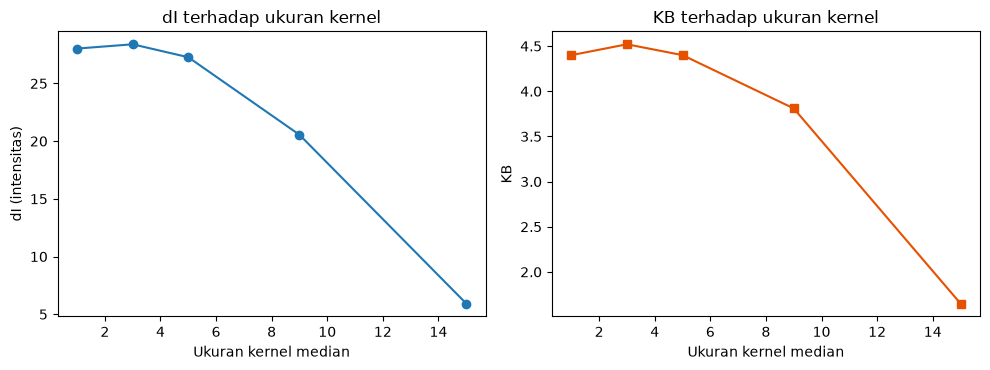

In [6]:
def selisih_rerata(kanal, mask_daun, mask_bercak):
    """dI = |rerata bercak - rerata daun sehat|, dalam satuan intensitas."""
    k = kanal.astype(float)
    sehat = (mask_daun > 0) & (mask_bercak == 0)
    return abs(k[mask_bercak > 0].mean() - k[sehat].mean())

label = pd.read_csv("../data/sintetis/label.csv")
baris = []
for nm in label[label.kelas == "ringan"].nama_file:
    g = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nm}"), cv2.COLOR_BGR2GRAY)
    md2 = cv2.imread(f"../data/sintetis/mask_daun/{nm}", 0)
    mb2 = cv2.imread(f"../data/sintetis/mask_bercak/{nm}", 0)
    for k in [1, 3, 5, 9, 15]:  # k = 1 berarti tanpa penapis
        out = g if k == 1 else cv2.medianBlur(g, k)
        baris.append([nm, k, selisih_rerata(out, md2, mb2), kontras_bercak(out, md2, mb2)])
hasil_median = pd.DataFrame(baris, columns=["nama", "kernel", "dI", "KB"])
rm = hasil_median.groupby("kernel")[["dI", "KB"]].mean().round(2)
print(rm); rm.to_csv("../hasil/b4_median_bercak_kecil.csv")
# luas bercak tersisa (piksel bercak yang masih berbeda >= 50% dari dI asli) untuk memperjelas
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].plot(rm.index, rm.dI, "o-"); ax[0].set_xlabel("Ukuran kernel median"); ax[0].set_ylabel("dI (intensitas)"); ax[0].set_title("dI terhadap ukuran kernel")
ax[1].plot(rm.index, rm.KB, "s-", color="#e65100"); ax[1].set_xlabel("Ukuran kernel median"); ax[1].set_ylabel("KB"); ax[1].set_title("KB terhadap ukuran kernel")
plt.tight_layout(); plt.savefig("../hasil/b4_di_kernel.png", dpi=100)
print(hasil_median[hasil_median.kernel == 1].sort_values("dI").head(3))

bercak terkecil di (400, 198) luas 81 piksel


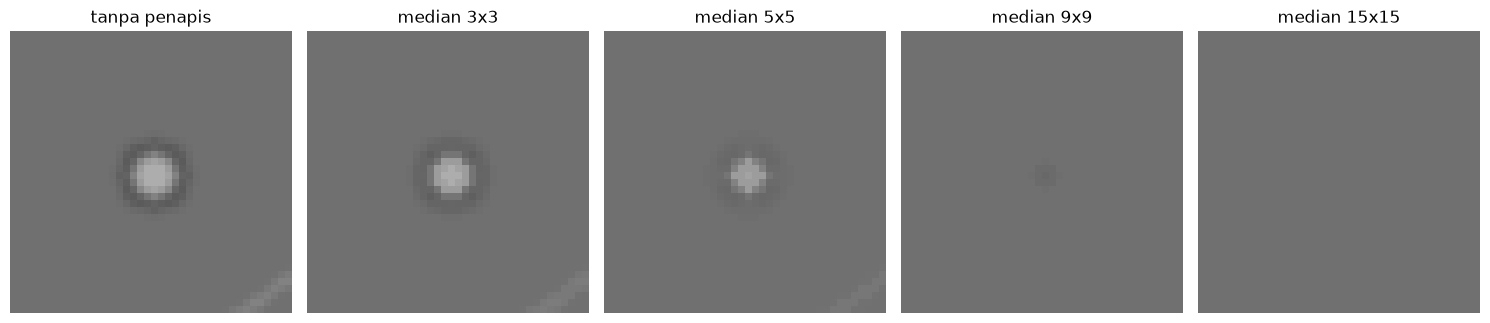

In [7]:
# potongan bercak yang diperbesar: pilih bercak kecil dari kelas ringan
nm = "teh_021.png"
g = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nm}"), cv2.COLOR_BGR2GRAY)
mb2 = cv2.imread(f"../data/sintetis/mask_bercak/{nm}", 0)
n_lab, lab_img, st, cen = cv2.connectedComponentsWithStats((mb2 > 0).astype(np.uint8))
i = 1 + int(np.argmin(st[1:, cv2.CC_STAT_AREA])) if n_lab > 1 else None
cx, cy = map(int, cen[i]); print("bercak terkecil di", (cx, cy), "luas", st[i, cv2.CC_STAT_AREA], "piksel")
y0, x0 = max(cy - 20, 0), max(cx - 20, 0)
fig, ax = plt.subplots(1, 5, figsize=(15, 3.4))
for a, k in zip(ax, [1, 3, 5, 9, 15]):
    out = g if k == 1 else cv2.medianBlur(g, k)
    a.imshow(out[y0:y0+40, x0:x0+40], cmap="gray", vmin=0, vmax=255, interpolation="nearest")
    a.set_title("tanpa penapis" if k == 1 else f"median {k}x{k}"); a.axis("off")
plt.tight_layout(); plt.savefig("../hasil/b4_crop_bercak.png", dpi=100)

## Langkah 4.5 Urutan meredam derau dan menajamkan

In [8]:
def unsharp(x, k=1.0):
    blur = cv2.GaussianBlur(x, (5, 5), 1.0)
    return cv2.addWeighted(x, 1 + k, blur, -k, 0)

noisy = derau["gauss_20"]
latar = md == 0  # area latar yang seharusnya rata
for nm, redam in {"Gaussian": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
                  "Median": lambda x: cv2.medianBlur(x, 5)}.items():
    A = redam(unsharp(noisy))  # tajamkan dulu, lalu redam
    B = unsharp(redam(noisy))  # redam dulu, lalu tajamkan
    print(f"{nm}: tajam->redam PSNR={cv2.PSNR(bersih, A):.2f} sigma_latar={A[latar].std():.1f} | "
          f"redam->tajam PSNR={cv2.PSNR(bersih, B):.2f} sigma_latar={B[latar].std():.1f}")
    if nm == "Gaussian":
        print("   selisih maks piksel A vs B (Gaussian):", int(np.abs(A.astype(int) - B.astype(int)).max()))

Gaussian: tajam->redam PSNR=30.35 sigma_latar=7.9 | redam->tajam PSNR=30.19 sigma_latar=8.1
   selisih maks piksel A vs B (Gaussian): 13
Median: tajam->redam PSNR=30.14 sigma_latar=8.0 | redam->tajam PSNR=31.11 sigma_latar=7.1


## Langkah 4.6 Penapis pada 12 citra kondisi normal (derau sensor bawaan)

In [9]:
normal = [f"teh_{i:03d}.png" for i in range(1, 61, 5)]
print(len(normal), "citra normal:", normal[:4], "...")
rows = []
for nm in normal:
    c = cv2.cvtColor(baca(f"../data/sintetis/citra/{nm}"), cv2.COLOR_BGR2GRAY)
    b = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nm}"), cv2.COLOR_BGR2GRAY)
    r = [nm, cv2.PSNR(b, c)]
    for pn, f in [("gauss_5", penapis["gauss_5"]), ("median_3", penapis["median_3"]), ("rerata_3", penapis["rerata_3"])]:
        r.append(cv2.PSNR(b, f(c)))
    rows.append(r)
t46 = pd.DataFrame(rows, columns=["citra", "PSNR_sebelum", "PSNR_gauss_5", "PSNR_median_3", "PSNR_rerata_3"]).round(2)
print(t46.to_string()); print(t46.iloc[:, 1:].mean().round(2))
t46.to_csv("../hasil/b4_psnr_12_normal.csv", index=False)

12 citra normal: ['teh_001.png', 'teh_006.png', 'teh_011.png', 'teh_016.png'] ...
          citra  PSNR_sebelum  PSNR_gauss_5  PSNR_median_3  PSNR_rerata_3
0   teh_001.png         32.94         41.62          40.03          41.06
1   teh_006.png         29.18         38.92          36.61          38.04
2   teh_011.png         31.39         40.59          38.67          39.88
3   teh_016.png         32.81         41.68          39.96          41.06
4   teh_021.png         32.51         41.11          39.58          40.57
5   teh_026.png         31.88         40.69          39.03          40.09
6   teh_031.png         31.72         40.58          38.95          40.00
7   teh_036.png         34.69         42.43          41.55          42.11
8   teh_041.png         28.95         38.29          36.26          37.55
9   teh_046.png         30.03         39.18          37.30          38.50
10  teh_051.png         29.05         38.51          36.41          37.72
11  teh_056.png         33.99 

## P4.6 Jumlah perkalian konvolusi manual

In [10]:
for ns, (w, h) in {"4000x3000": (4000, 3000), "640x480": (640, 480)}.items():
    print(ns, "kernel 5x5:", w*h*25, "perkalian =", f"{w*h*25/1e6:.1f} juta")
print("rasio:", (4000*3000)/(640*480))

4000x3000 kernel 5x5: 300000000 perkalian = 300.0 juta
640x480 kernel 5x5: 7680000 perkalian = 7.7 juta
rasio: 39.0625
